# Steam Store-Page Features and Review-Based Categories

This is an **exploratory, retrospective analysis** of 1,984 indie games. It examines associations between store-page features and review volume, then compares classifiers for review-count categories.

The original motivation was to investigate pre-launch prediction. However, these scraped snapshots were not verified as pre-launch observations, so this dataset does not establish pre-launch predictive performance. Review counts are a proxy for attention, not a measurement of sales or profit.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import zipfile

Matplotlib is building the font cache; this may take a moment.


In [2]:
df = pd.read_csv("steam_indie_games_dataset.csv")

### 1. Data Preparation

The CSV contains 1,984 unique AppIDs, including 675 zero-review games. **Zero-review games are retained** by the code below. `Log_Reviews = log1p(Review_Count)` is used as the OLS outcome; a log transform does not by itself guarantee normal residuals.

The notebook fills missing values with zero for its historical model. The separate model-comparison script fits imputation inside training folds. The current CSV has no missing cells.


In [3]:
df.head()

,AppID,Title,Price,Review_Count,Positive_Ratio,Gif_Count,Image_Count,Bullet_Points,Word_Count,Has_Demo,Tags
0,427520,Factorio,35.00,218588,0.97,0,0,3,315,1,Automation|Base Building|Resource Management|S...
1,976940,永冻之壳 The Shell of Permafrost,0.00,1190,0.98,0,6,0,225,0,Free to Play|RPG|Anime|Indie|RPGMaker
2,1740100,At Home Alone Final,0.00,7618,0.97,0,7,4,188,0,Free to Play|RPG|Pixel Graphics|Psychological ...
3,3880080,THE DREAM'S EXIT,0.99,0,0.00,0,0,0,83,0,RPG|Puzzle|Cyberpunk|Third Person|Adventure
4,3674270,FALLSTRUKTUR,0.00,490,0.97,0,0,8,55,0,Exploration|First-Person|Platformer|Action|3D ...


In [4]:
# df = df[df["Positive_Ratio"] > 0] 
df['Log_Reviews'] = np.log1p(df['Review_Count'])

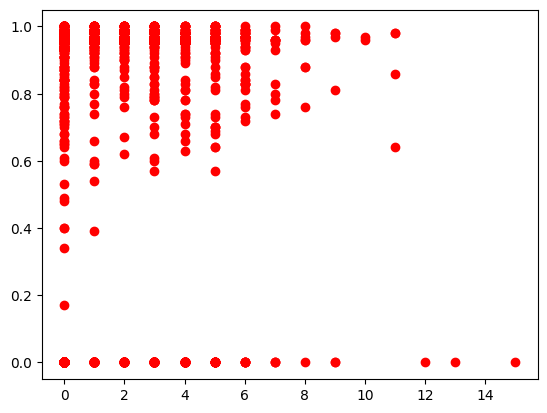

In [5]:
plt.plot(df.Gif_Count,df.Positive_Ratio,"ro")

### Exploratory Data Analysis

Spearman correlation measures rank-based **monotonic** association, rather than specifically linear association. These exploratory correlations do not identify causal effects. `Review_Count` and `Positive_Ratio` are displayed here for description; neither is used as an input to the original classifier.


In [6]:
numeric_cols = ['Price', 'Review_Count', 'Positive_Ratio', 'Gif_Count', 'Image_Count', 'Bullet_Points', 'Word_Count', 'Has_Demo']
corr_matrix = df[numeric_cols].corr(method='spearman') # Spearman tercih ettik!

Text(0.5, 1.0, 'Değişkenler Arası Spearman Korelasyonu')

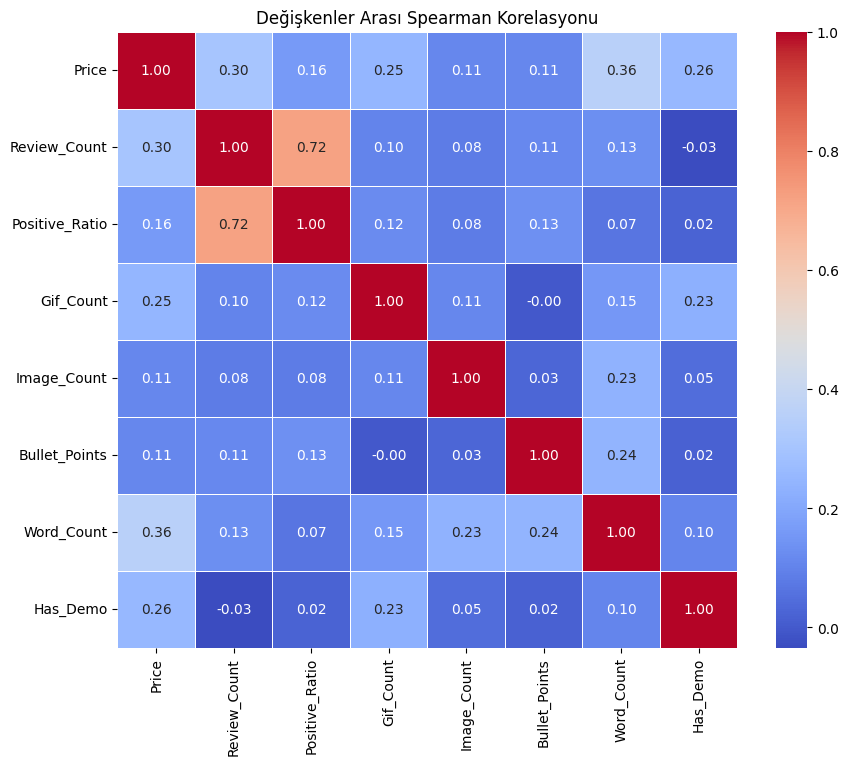

In [7]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Değişkenler Arası Spearman Korelasyonu")

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

df = df.fillna(0)

### Feature Engineering: Visual Density

The proposed metric is:

$$\text{Visual Density} = \frac{2 \times \text{GIF Count} + \text{Image Count}}{\text{Word Count} + 1}$$

The weighting of GIFs by two is a heuristic, not an estimated effect. The additional structure ratio is bullet points divided by `(Word_Count + 1)`.

The target categories follow the code's exact boundaries:

- **0:** 0-49 reviews.
- **1:** 50-999 reviews.
- **2:** 1,000 or more reviews.

These are descriptive review-volume bins, not validated definitions of commercial failure, sustainability or success.


In [9]:

# Hedef (0: Flop, 1: Alive, 2: Hit)
def classify_game(reviews):
    if reviews < 50: return 0
    elif reviews < 1000: return 1
    else: return 2

df['Success_Class'] = df['Review_Count'].apply(classify_game)
df['Visual_Density'] = ((df['Gif_Count'] * 2) + df['Image_Count']) / (df['Word_Count'] + 1)
df['Structure_Ratio'] = df['Bullet_Points'] / (df['Word_Count'] + 1)

features = ['Price', 'Visual_Density', 'Structure_Ratio', 'Has_Demo']

X = df[features]
y = df['Success_Class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf_model = RandomForestClassifier(n_estimators=300, random_state=42, max_depth=12)
rf_model.fit(X_train, y_train)

RandomForestClassifier(max_depth=12, n_estimators=300, random_state=42)

### Original Model: Results and Feature Importance

The original Random Forest uses price, visual density, structure ratio and demo availability. It excludes reviews and ratings as inputs, but this does not make the snapshots pre-launch data.

On the historical 397-game test split, accuracy is **52.90%** and macro-F1 is **0.471**. Recall for the middle category is only **0.189**. Impurity-based importance is approximately 0.339 for price and 0.331 for visual density: visual density is not the highest-ranked feature in this reproduced run.

Feature importance describes how this fitted model uses inputs. It does not establish statistical significance, causality, a nonlinear relationship or reliable out-of-sample performance. Continuous features can also be favored by impurity-based importance.


ORIGINAL REVIEW-CATEGORY MODEL
Accuracy: 52.90%
                precision    recall  f1-score   support

  0-49 reviews       0.55      0.75      0.63       160
50-999 reviews       0.43      0.19      0.26        95
 1000+ reviews       0.53      0.51      0.52       142

      accuracy                           0.53       397
     macro avg       0.50      0.48      0.47       397
  weighted avg       0.51      0.53      0.50       397

        Feature  Importance
          Price    0.338940
 Visual_Density    0.331119
Structure_Ratio    0.289465
       Has_Demo    0.040476


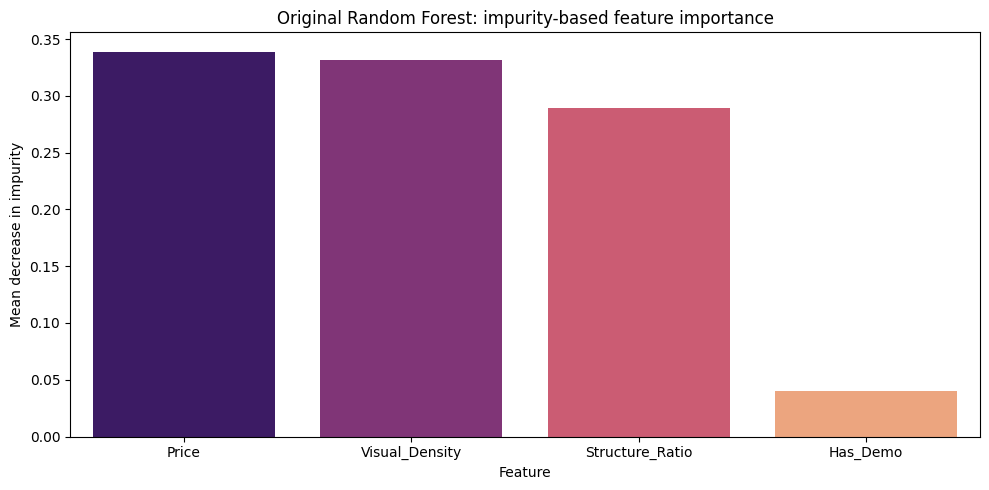

In [10]:
y_pred = rf_model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
class_names = ['0-49 reviews', '50-999 reviews', '1000+ reviews']
print('ORIGINAL REVIEW-CATEGORY MODEL')
print(f'Accuracy: {acc * 100:.2f}%')
print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]
importance_table = pd.DataFrame({'Feature': X.columns[indices], 'Importance': importances[indices]})
print(importance_table.to_string(index=False))

plt.figure(figsize=(10, 5))
sns.barplot(data=importance_table, x='Feature', y='Importance', hue='Feature', palette='magma', legend=False)
plt.title('Original Random Forest: impurity-based feature importance')
plt.ylabel('Mean decrease in impurity')
plt.tight_layout()
plt.show()


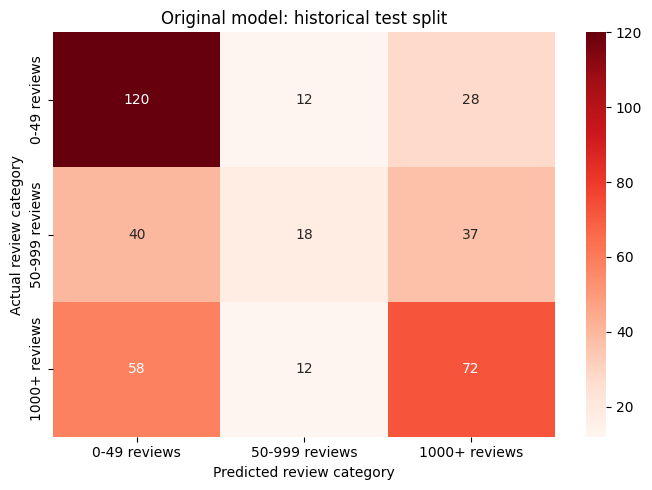

In [11]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', xticklabels=class_names, yticklabels=class_names)
plt.title('Original model: historical test split')
plt.ylabel('Actual review category')
plt.xlabel('Predicted review category')
plt.tight_layout()
plt.show()


### OLS and Random Forest Address Different Questions

The OLS model below regresses `log1p(Review_Count)` on visual density alone. The reproduced coefficient has **p = 0.135**, with **R² = 0.0011**. This specification does not provide evidence of a nonzero linear slope at the conventional 5% threshold; it does not prove that all relationships are absent.

OLS uses a continuous outcome, whereas the Random Forest predicts thresholded review categories with several inputs. Their outputs do not form a contradiction. A high model-specific feature importance alongside a nonsignificant OLS coefficient **does not prove nonlinearity** or identify an optimal visual density.


In [12]:

import pandas as pd
import numpy as np
import statsmodels.api as sm

df['Visual_Density'] = ((df['Gif_Count'] * 2) + df['Image_Count']) / (df['Word_Count'] + 1)
df['Log_Reviews'] = np.log1p(df['Review_Count'])

X = df['Visual_Density']
y = df['Log_Reviews']

X = sm.add_constant(X)

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            Log_Reviews   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     2.234
Date:                Sat, 07 Nov 2026   Prob (F-statistic):              0.135
Time:                        00:56:26   Log-Likelihood:                -5479.6
No. Observations:                1984   AIC:                         1.096e+04
Df Residuals:                    1982   BIC:                         1.097e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              4.6257      0.090     51.

In [13]:
def predict_my_game(price, gif_count, img_count, bullet_points, word_count, has_demo):
    """Explore the original model; this is not a validated launch forecast."""
    input_data = pd.DataFrame({
        'Price': [price],
        'Visual_Density': [(gif_count * 2 + img_count) / (word_count + 1)],
        'Structure_Ratio': [bullet_points / (word_count + 1)],
        'Has_Demo': [has_demo],
    })
    prediction = rf_model.predict(input_data)[0]
    probabilities = rf_model.predict_proba(input_data)[0]
    names = ['0-49 reviews', '50-999 reviews', '1000+ reviews']
    print('HYPOTHETICAL INPUT: ORIGINAL MODEL RESPONSE')
    print(f'Predicted review category: {names[prediction]}')
    print(f'Uncalibrated model probability for 1000+ reviews: {probabilities[2]:.1%}')
    print('This output is not evidence that changing the page will change its reviews or sales.\n')

predict_my_game(price=15, gif_count=6, img_count=10, bullet_points=8, word_count=400, has_demo=1)
predict_my_game(price=5, gif_count=0, img_count=2, bullet_points=0, word_count=800, has_demo=0)


HYPOTHETICAL INPUT: ORIGINAL MODEL RESPONSE
Predicted review category: 50-999 reviews
Uncalibrated model probability for 1000+ reviews: 38.7%
This output is not evidence that changing the page will change its reviews or sales.

HYPOTHETICAL INPUT: ORIGINAL MODEL RESPONSE
Predicted review category: 0-49 reviews
Uncalibrated model probability for 1000+ reviews: 6.2%
This output is not evidence that changing the page will change its reviews or sales.



## Conclusion for the Original Analysis

This dataset does not establish that visual density causes success, that poor visual design guarantees failure, or that the model predicts commercial outcomes before launch. The original classifier achieves 52.90% accuracy on one historical split and has weak middle-category recall.

The notebook's original claims about a proven nonlinear relationship, guaranteed failure, asset flips and Steam algorithm behavior were not supported by the analysis. Asset quality and gameplay were not measured, so those explanations remain untested hypotheses.

The OLS result and classifier performance should be interpreted separately. Further work needs baseline comparisons, training-only validation and temporally appropriate data. The following development experiments add those comparisons without turning the historical dataset into independent external evidence.


## Additional Model Experiments

`evaluate_models.py` compares 26 fixed candidates in two development stages. Stage one compares 15 classifiers and feature sets; stage two adds 11 candidates with title text, ordered classification, direct log-review regression or boosted tag features.

All choices use five stratified folds within the original 1,587 training rows. Preprocessing and text vocabularies are fitted inside each fold. The 397 historical test rows are excluded from those fits. The accuracy winner, numeric-only winner and macro-F1 winner are selected using CV scores; the original and stage-one models remain reference comparisons.

Tags and title text broaden the question beyond visual composition. The second stage and secondary macro-F1 comparison were motivated by earlier results, so this is adaptive development. The historical holdout has already been examined; these are not fresh confirmatory or pre-launch estimates.

Regenerate the report with `python evaluate_models.py` before running this section after any dataset change.


In [14]:
import hashlib
import json
from pathlib import Path

report = json.loads(Path('reports/model_comparison.json').read_text())
dataset_hash = hashlib.sha256(Path('steam_indie_games_dataset.csv').read_bytes()).hexdigest()
assert report['dataset_sha256'] == dataset_hash, 'Dataset changed: rerun evaluate_models.py'

comparison = pd.DataFrame([
    {'Model': name, 'Test accuracy': result['accuracy'], 'Macro F1': result['macro_f1'],
     'Balanced accuracy': result['balanced_accuracy'],
     'Middle-category recall': result['classification_report']['50-999 reviews']['recall']}
    for name, result in report['heldout'].items()
])
print('Historical test comparison (not independent external validation):')
print(comparison.round(4).to_string(index=False))
print('\nCV accuracy selection:', report['selected_model'])
print('CV macro-F1 selection:', report['selected_macro_f1_model'])

cv_table = pd.DataFrame(report['cross_validation']).sort_values('cv_accuracy_mean', ascending=False)
print('\nTraining-only cross-validation results:')
print(cv_table[['name', 'stage', 'cv_accuracy_mean', 'cv_accuracy_std', 'cv_macro_f1_mean']].round(4).to_string(index=False))


Historical test comparison (not independent external validation):
                               Model  Test accuracy  Macro F1  Balanced accuracy  Middle-category recall
                   majority_baseline         0.4030    0.1915             0.3333                  0.0000
                         original_rf         0.5290    0.4713             0.4822                  0.1895
                   rf_numeric_leaf10         0.5038    0.4100             0.4439                  0.0526
                     rf_numeric_tags         0.5919    0.4528             0.5164                  0.0105
log_reviews_extra_trees_numeric_tags         0.5743    0.5434             0.5520                  0.4632
          logistic_numeric_tags_C1.0         0.5844    0.5309             0.5385                  0.2316

CV accuracy selection: rf_numeric_tags
CV macro-F1 selection: log_reviews_extra_trees_numeric_tags

Training-only cross-validation results:
                                name  stage  cv_accuracy_m

### What These Experiments Can and Cannot Show

Accuracy and macro-F1 can favor different models, especially when the middle review category is difficult. An accuracy increase that loses most middle-category recall is not an unqualified improvement. The report retains class-level metrics and unsuccessful trials.

Bootstrap intervals describe paired accuracy differences on this historical sample; they do not account for adaptive model selection, sampling bias or temporal confounding. Winning CV scores may be optimistic after comparing many candidates.

Stronger follow-up work requires new data: verified pre-launch page snapshots, review counts measured at a common post-launch horizon, release timestamps and developer/publisher grouping. Actual description text and visual content are absent from the CSV; counts and game titles cannot substitute for those measurements. Such data may help, but higher accuracy is not guaranteed.

References: [scikit-learn: common pitfalls and leakage](https://scikit-learn.org/stable/common_pitfalls.html), [cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html), [feature-importance limitations](https://scikit-learn.org/stable/modules/permutation_importance.html).
